## TASK 1

### S1. Environment Setup / 環境設定
---
本段程式主要負責初始化本次 SAR 淹水偵測實驗所需的環境與參數。首先設定 GDAL/COG 的網路讀取參數，提高從 Microsoft Planetary Computer 串流讀取衛星影像時的穩定性，避免因網路中斷或大型影像讀取造成錯誤。

接著，程式會讀取 `.env` 檔案中的實驗參數，包括研究區範圍、災前與災後日期、SAR 門檻、NDWI 門檻、坡度門檻與最小水體面積門檻。這樣可以讓主要程式不需要手動修改參數，提高實驗的可重現性。

最後，程式載入本次分析會使用的 Python 套件，並連接 Microsoft Planetary Computer STAC catalog，讓後續可以直接搜尋與串流讀取 Sentinel-1、Sentinel-2 與 DEM 資料。

本段完成後，後續分析將使用 `.env` 中設定的研究範圍與參數進行災前/災後 SAR 影像搜尋、水體偵測、光學比較與 DEM 地形檢查。

In [1]:
import os, time, warnings
warnings.filterwarnings('ignore')

# ---- GDAL/COG 穩定性設定 ----
os.environ.setdefault('GDAL_HTTP_MAX_RETRY', '5')
os.environ.setdefault('GDAL_HTTP_RETRY_DELAY', '2')
os.environ.setdefault('GDAL_HTTP_TIMEOUT', '60')
os.environ.setdefault('GDAL_HTTP_MULTIRANGE', 'YES')
os.environ.setdefault('GDAL_HTTP_MERGE_CONSECUTIVE_RANGES', 'YES')
os.environ.setdefault('VSI_CACHE', 'TRUE')
os.environ.setdefault('VSI_CACHE_SIZE', '1000000000')
os.environ.setdefault('CPL_VSIL_CURL_ALLOWED_EXTENSIONS', '.tif,.TIF,.tiff')

# ---- 讀取 .env（不依賴額外套件）----
def load_env(path=".env"):
    if not os.path.exists(path):
        print(f"⚠️ {path} not found, using existing environment/defaults")
        return
    with open(path, "r", encoding="utf-8") as f:
        for raw in f:
            line = raw.strip()
            if not line or line.startswith("#") or "=" not in line:
                continue
            k, v = line.split("=", 1)
            k = k.strip()
            v = v.strip()
            # 支援 inline 註解，例如 SAR_THRESHOLD=-18  # comment
            if "#" in v:
                v = v.split("#", 1)[0].strip()
            os.environ[k] = v

load_env(".env")

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from scipy.ndimage import median_filter
import xarray as xr
import rioxarray as rxr
import pystac_client
import planetary_computer as pc
import stackstac

plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei', 'PingFang TC', 'Heiti TC', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=pc.sign_inplace,
)

# ---- 從 .env 讀參數 ----
HUALIEN_BBOX = [
    float(os.getenv("BBOX_WEST")),
    float(os.getenv("BBOX_SOUTH")),
    float(os.getenv("BBOX_EAST")),
    float(os.getenv("BBOX_NORTH")),
]
PRE_DATE_RANGE = os.getenv("PRE_DATE_RANGE")
POST_DATE_RANGE = os.getenv("POST_DATE_RANGE")

SAR_THRESHOLD = float(os.getenv("SAR_THRESHOLD", "-18"))
NDWI_THRESHOLD = float(os.getenv("NDWI_THRESHOLD", "0.3"))
SLOPE_THRESHOLD = float(os.getenv("SLOPE_THRESHOLD", "25"))
MIN_WATER_PIXELS = int(os.getenv("MIN_WATER_PIXELS", "50"))

OUTPUT_DIR = "output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

def safe_compute(lazy_arr, tries=4):
    """Retry wrapper for COG reads."""
    from rasterio.errors import RasterioIOError
    last_err = None
    for attempt in range(tries):
        try:
            return lazy_arr.compute()
        except (RasterioIOError, RuntimeError, OSError) as e:
            last_err = e
            time.sleep(2 ** attempt)
    raise RuntimeError(f"COG read failed after {tries} attempts: {last_err}")

print("✅ Environment ready")
print(f"   HUALIEN_BBOX: {HUALIEN_BBOX}")
print(f"   PRE_DATE_RANGE: {PRE_DATE_RANGE}")
print(f"   POST_DATE_RANGE): {POST_DATE_RANGE}")


✅ Environment ready
   HUALIEN_BBOX: [121.2574, 23.6546, 121.4984, 23.7447]
   PRE_DATE_RANGE: 2025-09-01/2025-11-05
   POST_DATE_RANGE): 2025-11-12/2025-11-30


### S2. Sentinel-1 RTC Search and Orbit Selection / SAR 影像搜尋與軌道選擇
---
本段程式負責搜尋災前與災後的 Sentinel-1 RTC SAR 影像。Sentinel-1 屬於雷達影像，不受雲層遮蔽影響，因此適合用於颱風或豪雨後的淹水與堰塞湖偵測。

程式會先根據 `.env` 中設定的研究區範圍 `HUALIEN_BBOX`、災前日期 `PRE_DATE_RANGE` 與災後日期 `POST_DATE_RANGE`，分別搜尋可用的 Sentinel-1 RTC 影像。如果任一時期找不到影像，程式會直接停止，避免後續分析使用空資料。

接著，程式會檢查災前與災後影像的軌道方向，也就是 `ascending` 或 `descending`。由於 SAR 是側視雷達，不同軌道方向會造成不同的觀測角度與回波特徵，因此災前與災後影像不能混用不同軌道。程式會找出兩個時期共同擁有的軌道方向，並選擇影像數量最多的共同軌道作為後續分析使用。

完成本段後，後續的 SAR 變化偵測會使用相同軌道方向的影像，以降低觀測幾何差異造成的誤判。

In [2]:
import pystac_client, planetary_computer as pc, stackstac
from collections import Counter

catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=pc.sign_inplace,
)

def search_s1_items(date_range, bbox, label=""):
    search = catalog.search(
        collections=["sentinel-1-rtc"],
        bbox=bbox,
        datetime=date_range,
    )
    items = list(search.items())
    print(f"{label} found {len(items)} scenes")
    if len(items) == 0:
        raise ValueError(f"No Sentinel-1 items in {label} ({date_range})")
    return items

# 1) 分別搜尋災前、災後
pre_items = search_s1_items(PRE_DATE_RANGE, HUALIEN_BBOX, "PRE")
post_items = search_s1_items(POST_DATE_RANGE, HUALIEN_BBOX, "POST")

# 2) 找兩邊共同可用的軌道方向（避免混用升/降軌）
pre_orbits = {it.properties.get("sat:orbit_state", "unknown") for it in pre_items}
post_orbits = {it.properties.get("sat:orbit_state", "unknown") for it in post_items}
common_orbits = pre_orbits.intersection(post_orbits)

print("PRE orbits :", pre_orbits)
print("POST orbits:", post_orbits)
print("Common     :", common_orbits)

if len(common_orbits) == 0:
    raise ValueError("PRE/POST 沒有共同軌道方向，請調整日期區間。")

# 3) 選一個共同軌道（預設選資料較多者）
orbit_counts = {}
for orb in common_orbits:
    orbit_counts[orb] = sum(it.properties.get("sat:orbit_state") == orb for it in pre_items) + \
                        sum(it.properties.get("sat:orbit_state") == orb for it in post_items)
selected_orbit = max(orbit_counts, key=orbit_counts.get)
print("Selected orbit:", selected_orbit)


PRE found 19 scenes
POST found 5 scenes
PRE orbits : {'descending', 'ascending'}
POST orbits: {'descending', 'ascending'}
Common     : {'descending', 'ascending'}
Selected orbit: descending


### S3. Stream Sentinel-1 RTC Data / 串流讀取 SAR 資料
---
本段程式定義 `stream_sar()` 函式，用來從 Microsoft Planetary Computer 串流讀取 Sentinel-1 RTC 影像。函式會根據指定的 STAC item、研究區範圍與波段，將 SAR 資料讀成 lazy xarray 格式，方便後續分析。

這裡預設讀取 `vv` 波段，因為 VV backscatter 對水體偵測很常用。水面通常會造成鏡面反射，使回到衛星的訊號較弱，因此 VV 值較低，可用來判斷可能的水體或淹水區。

程式使用 `stackstac.stack()` 將資料投影到 UTM Zone 51N，並設定 10 公尺解析度，與後續面積計算一致。與 Sentinel-2 光學影像不同，Sentinel-1 RTC 已經是校正後的線性 backscatter，因此不需要再除以 10000。

本段完成後，後續可以用 `stream_sar()` 讀取災前與災後 SAR 影像，並進一步轉換成 dB 進行水體偵測。

In [3]:
def stream_sar(item, bands=['vv'], bbox=HUALIEN_BBOX):
    """Stream Sentinel-1 RTC as lazy xarray (linear backscatter)."""
    signed = pc.sign(item)
    cube = stackstac.stack(
        [signed],
        assets=bands,
        epsg=32651,          # UTM 51N
        resolution=10,
        bounds_latlon=bbox,
        chunksize=2048,
    ).squeeze('time')        # S1 不需要 /10000
    return cube

print('stream_sar() ready')


stream_sar() ready


### S4. Scene Selection and dB Conversion / 場景選擇與 dB 轉換
---
本段程式會先列出災前與災後 Sentinel-1 RTC 影像中共同可用的軌道方向，並只保留同一軌道的影像候選清單。由於 SAR 是側視雷達，ascending 與 descending 的觀測幾何不同，若災前與災後混用不同軌道，可能會把觀測角度造成的回波差異誤判為地表變化。因此，本實驗先固定共同軌道，再進行後續比較。

接著，程式會列出該軌道下所有災前與災後候選影像，包含影像時間與 STAC item ID，方便手動確認與選擇。目前程式預設選擇清單中的第一張災前影像與第一張災後影像，若需要更精準的時間配對，可以手動修改索引值。

最後，程式讀取選定影像的 VV 波段。Sentinel-1 RTC 原始值為線性 backscatter，因此需要轉換成 dB：

\[
dB = 10 \times \log_{10}(\text{linear backscatter})
\]

轉換前會先將小於或等於 0 的無效值設為 `NaN`，避免 `log10` 產生無限值或錯誤。完成後會輸出災前與災後影像的大小與 dB 範圍，作為資料是否正常的基本檢查。

In [4]:
# [S4] List scenes first, then pick manually

if not pre_items or not post_items:
    raise ValueError("災前或災後無場景！請回 [S2] 檢查")

# 1) 先列出共同軌道
pre_orbits = {it.properties.get("sat:orbit_state", "").lower() for it in pre_items}
post_orbits = {it.properties.get("sat:orbit_state", "").lower() for it in post_items}
common_orbits = sorted(list(pre_orbits.intersection(post_orbits)))
if not common_orbits:
    raise ValueError("災前/災後沒有共同軌道方向，請調整日期範圍")

print("Common orbits:", common_orbits)

# 2) 指定你要看的軌道（先用第一個，也可手動改成 'ascending' / 'descending'）
selected_orbit = common_orbits[0]
print(f"\nSelected orbit: {selected_orbit}")

pre_same = sorted(
    [it for it in pre_items if it.properties.get("sat:orbit_state", "").lower() == selected_orbit],
    key=lambda x: x.properties["datetime"]
)
post_same = sorted(
    [it for it in post_items if it.properties.get("sat:orbit_state", "").lower() == selected_orbit],
    key=lambda x: x.properties["datetime"]
)

print(f"\nPRE candidates ({len(pre_same)}):")
for i, it in enumerate(pre_same):
    dt = it.properties.get("datetime", "")[:19]
    print(f"[{i:02d}] {dt} | {it.id}")

print(f"\nPOST candidates ({len(post_same)}):")
for i, it in enumerate(post_same):
    dt = it.properties.get("datetime", "")[:19]
    print(f"[{i:02d}] {dt} | {it.id}")


pre_item = pre_same[0]
post_item = post_same[0]

print(f"\n✅ Chosen PRE : [{0}] {pre_item.properties['datetime'][:19]} | {pre_item.id}")
print(f"✅ Chosen POST: [{0}] {post_item.properties['datetime'][:19]} | {post_item.id}")

# 4) 讀取並轉 dB
print("\nLoading pre-disaster VV...")
vv_pre_linear = safe_compute(stream_sar(pre_item, ["vv"]))
vv_pre = vv_pre_linear.values.squeeze().astype(np.float32)
vv_pre = np.where(vv_pre > 0, vv_pre, np.nan)
vv_pre_db = 10 * np.log10(vv_pre)

print("Loading post-disaster VV...")
vv_post_linear = safe_compute(stream_sar(post_item, ["vv"]))
vv_post = vv_post_linear.values.squeeze().astype(np.float32)
vv_post = np.where(vv_post > 0, vv_post, np.nan)
vv_post_db = 10 * np.log10(vv_post)

print(f"\nPre  shape: {vv_pre_db.shape}, range: {np.nanmin(vv_pre_db):.1f} ~ {np.nanmax(vv_pre_db):.1f} dB")
print(f"Post shape: {vv_post_db.shape}, range: {np.nanmin(vv_post_db):.1f} ~ {np.nanmax(vv_post_db):.1f} dB")


Common orbits: ['ascending', 'descending']

Selected orbit: ascending

PRE candidates (8):
[00] 2025-09-06T10:01:35 | S1A_IW_GRDH_1SDV_20250906T100123_20250906T100148_060866_07944A_rtc
[01] 2025-09-18T10:01:36 | S1A_IW_GRDH_1SDV_20250918T100123_20250918T100148_061041_079B51_rtc
[02] 2025-09-30T10:01:36 | S1A_IW_GRDH_1SDV_20250930T100123_20250930T100148_061216_07A25E_rtc
[03] 2025-10-12T10:01:36 | S1A_IW_GRDH_1SDV_20251012T100124_20251012T100149_061391_07A969_rtc
[04] 2025-10-18T10:00:31 | S1C_IW_GRDH_1SDV_20251018T100018_20251018T100043_004615_009205_rtc
[05] 2025-10-24T10:01:36 | S1A_IW_GRDH_1SDV_20251024T100123_20251024T100148_061566_07B06F_rtc
[06] 2025-10-30T10:00:30 | S1C_IW_GRDH_1SDV_20251030T100018_20251030T100043_004790_00975D_rtc
[07] 2025-11-05T10:01:36 | S1A_IW_GRDH_1SDV_20251105T100123_20251105T100148_061741_07B75F_rtc

POST candidates (2):
[00] 2025-11-23T10:00:29 | S1C_IW_GRDH_1SDV_20251123T100017_20251123T100042_005140_00A313_rtc
[01] 2025-11-29T10:01:34 | S1A_IW_GRDH_1S

### S5. SAR Before–After Visualization / SAR 災前災後視覺化比較
---
本段程式將災前與災後的 Sentinel-1 VV backscatter 影像，以及兩者的差異圖整理成 1×3 面板，用來觀察堰塞湖或新增水體在 SAR 影像中的變化。

左圖為災前 VV dB 影像，作為事件前的地表基準；中圖為災後 VV dB 影像，用來觀察事件後是否出現低回波區。SAR 影像中，水面通常因鏡面反射造成回波較弱，因此會呈現較低的 dB 值，也就是影像中較暗的區域。

右圖為災後減災前的差異圖：

\[
\Delta dB = VV_{post} - VV_{pre}
\]

若 \(\Delta dB < 0\)，代表災後 backscatter 下降，可能表示地表變得更平滑或形成水體。本圖使用 `RdBu_r` 色帶，使負值顯示為藍色，方便辨識可能新增的低回波水體區域。

本段輸出的圖可作為後續 threshold 偵測與水體 mask 建立前的視覺檢查。

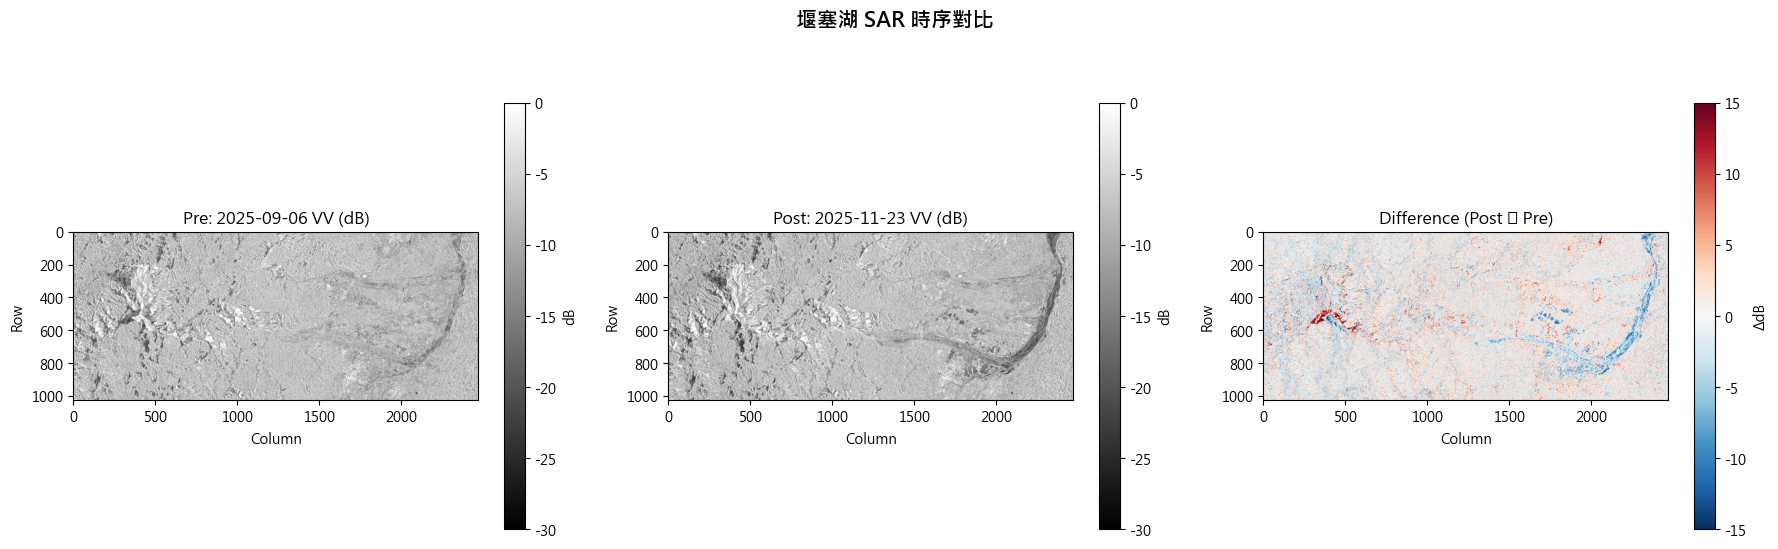

In [5]:
pre_date = pre_item.properties['datetime'][:10]
post_date = post_item.properties['datetime'][:10]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

im0 = axes[0].imshow(vv_pre_db, cmap='gray', vmin=-30, vmax=0)
axes[0].set_title(f'Pre: {pre_date} VV (dB)')
plt.colorbar(im0, ax=axes[0], shrink=0.8, label='dB')

im1 = axes[1].imshow(vv_post_db, cmap='gray', vmin=-30, vmax=0)
axes[1].set_title(f'Post: {post_date} VV (dB)')
plt.colorbar(im1, ax=axes[1], shrink=0.8, label='dB')

diff_db = vv_post_db - vv_pre_db
im2 = axes[2].imshow(diff_db, cmap='RdBu_r', vmin=-15, vmax=15)  # 反轉：負值=藍
axes[2].set_title('Difference (Post − Pre)')
plt.colorbar(im2, ax=axes[2], shrink=0.8, label='ΔdB')

for ax in axes:
    ax.set_xlabel('Column')
    ax.set_ylabel('Row')

plt.suptitle('堰塞湖 SAR 時序對比', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/W10_sar_before_after.png', dpi=150, bbox_inches='tight')
plt.show()


### S6. Threshold Sweep and Morphological Cleanup / 門檻測試與水體遮罩清理
---
本段程式負責建立最終的 SAR 水體遮罩。由於 SAR 影像容易受到 speckle 雜訊影響，程式首先對災後 VV dB 影像套用 5×5 median filter，使低回波水體區域更連續，也減少零碎雜訊造成的誤判。

接著，程式會繪製災後 VV backscatter 的直方圖，觀察像素值分布，並掃描多組水體判斷門檻，包括 `-20`、`-18`、`-16`、`-14` 和 `-12 dB`。不同門檻會影響水體偵測結果：較嚴格的門檻會保留較低回波的水體核心，但可能低估面積；較寬鬆的門檻會抓到更多候選水體，但也可能增加假陽性。

每一組門檻都會經過兩個後處理步驟。第一步是 morphological opening，用來移除孤立或破碎的小像素；第二步是 connected component filtering，只保留面積大於 `MIN_WATER_PIXELS` 的連通水體區塊。這樣可以避免把零碎 speckle 或小型低回波雜訊誤判成水體。

最後，程式將各門檻的水體像素數、面積、保留區塊數、移除區塊數與水體區平均 dB 整理成表格，並指定 `BEST_THRESHOLD = -16` 作為後續分析使用的最終門檻。最終輸出的 `sar_water` 是清理後的 SAR 水體遮罩，後續將用於光學比較、融合信心圖與面積統計。

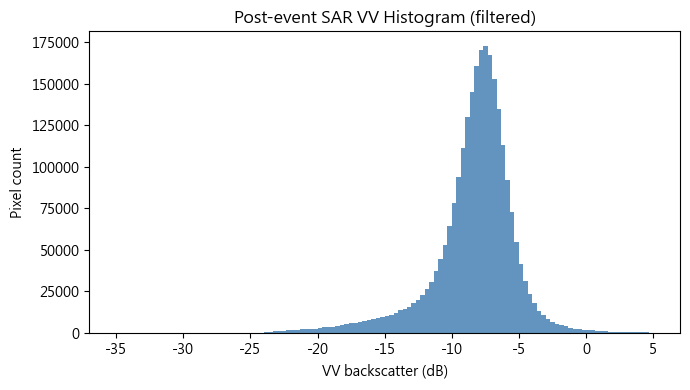

 threshold_db  water_px_final  flood_area_km2  regions_kept  regions_removed  mean_db_in_flood
          -20           12294          1.2294            76              160        -21.843702
          -18           32002          3.2002           149              249        -20.350813
          -16           66354          6.6354           232              335        -18.816694
          -14          118418         11.8418           339              536        -17.322014
          -12          206654         20.6654           582              973        -15.644286


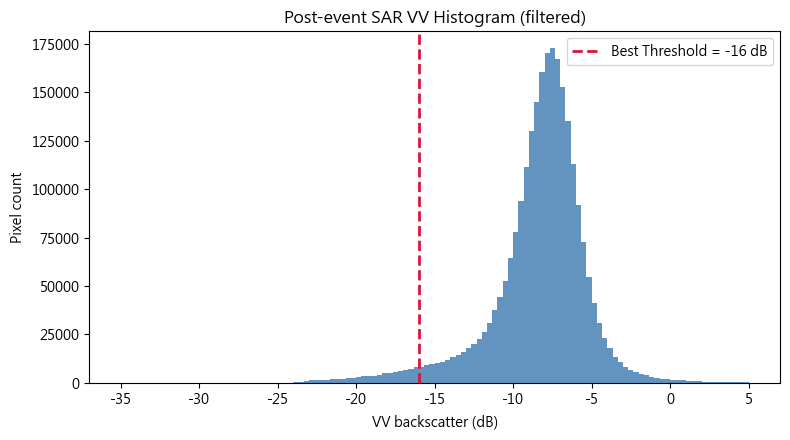

Best threshold: -16 dB
Final water pixels: 66,354
Flood area: 6.6354 km²
Mean dB in flood zone: -18.82 dB
✅ Histogram saved: output/W10_histogram_best_threshold.png


In [6]:
# [S6] Threshold sweep + Morphological cleanup + Final selection
from scipy.ndimage import median_filter, binary_opening, label
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ---------- A) 先做 speckle filter ----------
sar_filtered = median_filter(np.where(np.isfinite(vv_post_db), vv_post_db, 0.0), size=5)

# ---------- B) 先看直方圖 ----------
plt.figure(figsize=(7, 4))
vals = sar_filtered[np.isfinite(sar_filtered)]
plt.hist(vals.ravel(), bins=120, range=(-35, 5), color="steelblue", alpha=0.85)
plt.xlabel("VV backscatter (dB)")
plt.ylabel("Pixel count")
plt.title("Post-event SAR VV Histogram (filtered)")
plt.tight_layout()
plt.show()

# ---------- C) 掃描多組閾值 ----------
threshold_list = [-20, -18, -16, -14, -12]
px_area_km2 = (10 * 10) / 1_000_000  # 10m x 10m

results = {}
summary_rows = []

for th in threshold_list:
    raw = (sar_filtered < th).astype(np.uint8)

    opened = binary_opening(
        raw, structure=np.ones((3, 3), dtype=np.uint8), iterations=1
    ).astype(np.uint8)

    labeled, n_features = label(opened)
    final_mask = np.zeros_like(opened, dtype=np.uint8)

    kept, removed = 0, 0
    for rid in range(1, n_features + 1):
        sz = int((labeled == rid).sum())
        if sz >= MIN_WATER_PIXELS:
            final_mask[labeled == rid] = 1
            kept += 1
        else:
            removed += 1

    water_px = int(final_mask.sum())
    area_km2 = water_px * px_area_km2
    mean_db = float(np.nanmean(sar_filtered[final_mask == 1])) if water_px > 0 else np.nan

    results[th] = {"raw": raw, "opened": opened, "final": final_mask}
    summary_rows.append({
        "threshold_db": th,
        "water_px_final": water_px,
        "flood_area_km2": area_km2,
        "regions_kept": kept,
        "regions_removed": removed,
        "mean_db_in_flood": mean_db
    })

summary_df = pd.DataFrame(summary_rows).sort_values("threshold_db")
print(summary_df.to_string(index=False))

# ---------- D) 這裡重新選最佳閾值 ----------
BEST_THRESHOLD = -16

sar_water = results[BEST_THRESHOLD]["final"].copy()
SAR_THRESHOLD = BEST_THRESHOLD  # 同步更新後續流程使用的變數

water_px = int(sar_water.sum())
flood_km2 = water_px * px_area_km2
mean_db_flood = float(np.nanmean(sar_filtered[sar_water == 1])) if water_px > 0 else np.nan

# ---------- E) 輸出最終直方圖（含最佳門檻）到 output ----------
hist_path = f"{OUTPUT_DIR}/W10_histogram_best_threshold.png"

plt.figure(figsize=(8, 4.5))
vals = sar_filtered[np.isfinite(sar_filtered)]
plt.hist(vals.ravel(), bins=120, range=(-35, 5), color="steelblue", alpha=0.85)
plt.axvline(SAR_THRESHOLD, color="crimson", linestyle="--", linewidth=2,
            label=f"Best Threshold = {SAR_THRESHOLD} dB")
plt.xlabel("VV backscatter (dB)")
plt.ylabel("Pixel count")
plt.title("Post-event SAR VV Histogram (filtered)")
plt.legend()
plt.tight_layout()
plt.savefig(hist_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Best threshold: {SAR_THRESHOLD} dB")
print(f"Final water pixels: {water_px:,}")
print(f"Flood area: {flood_km2:.4f} km²")
print(f"Mean dB in flood zone: {mean_db_flood:.2f} dB")
print(f"✅ Histogram saved: {hist_path}")


### S7. Lab 1 SAR Flood Detection Visualization / SAR 水體偵測成果圖
---
本段程式將 SAR 水體偵測流程整理成 2×2 面板圖，作為 Lab 1 的主要視覺化成果。四張子圖分別呈現原始災後 SAR、濾波後 SAR、水體遮罩，以及水體遮罩疊加在 SAR 影像上的結果。

左上圖顯示原始災後 VV dB 影像，可觀察水體或低回波區域的位置，但影像中仍可能存在 speckle 雜訊。右上圖顯示經過 5×5 median filter 後的 SAR 影像，雜訊較少，水體區域也更連續。

左下圖是根據最佳門檻 `SAR_THRESHOLD` 產生並經過形態學清理後的水體 mask，其中藍色代表被判定為水體的像素。右下圖則將水體 mask 疊加回濾波後的 SAR 影像，用來檢查偵測出的水體是否落在低回波區域，並判斷結果是否合理。

本圖可用來展示從 SAR 影像到最終水體偵測結果的完整流程。

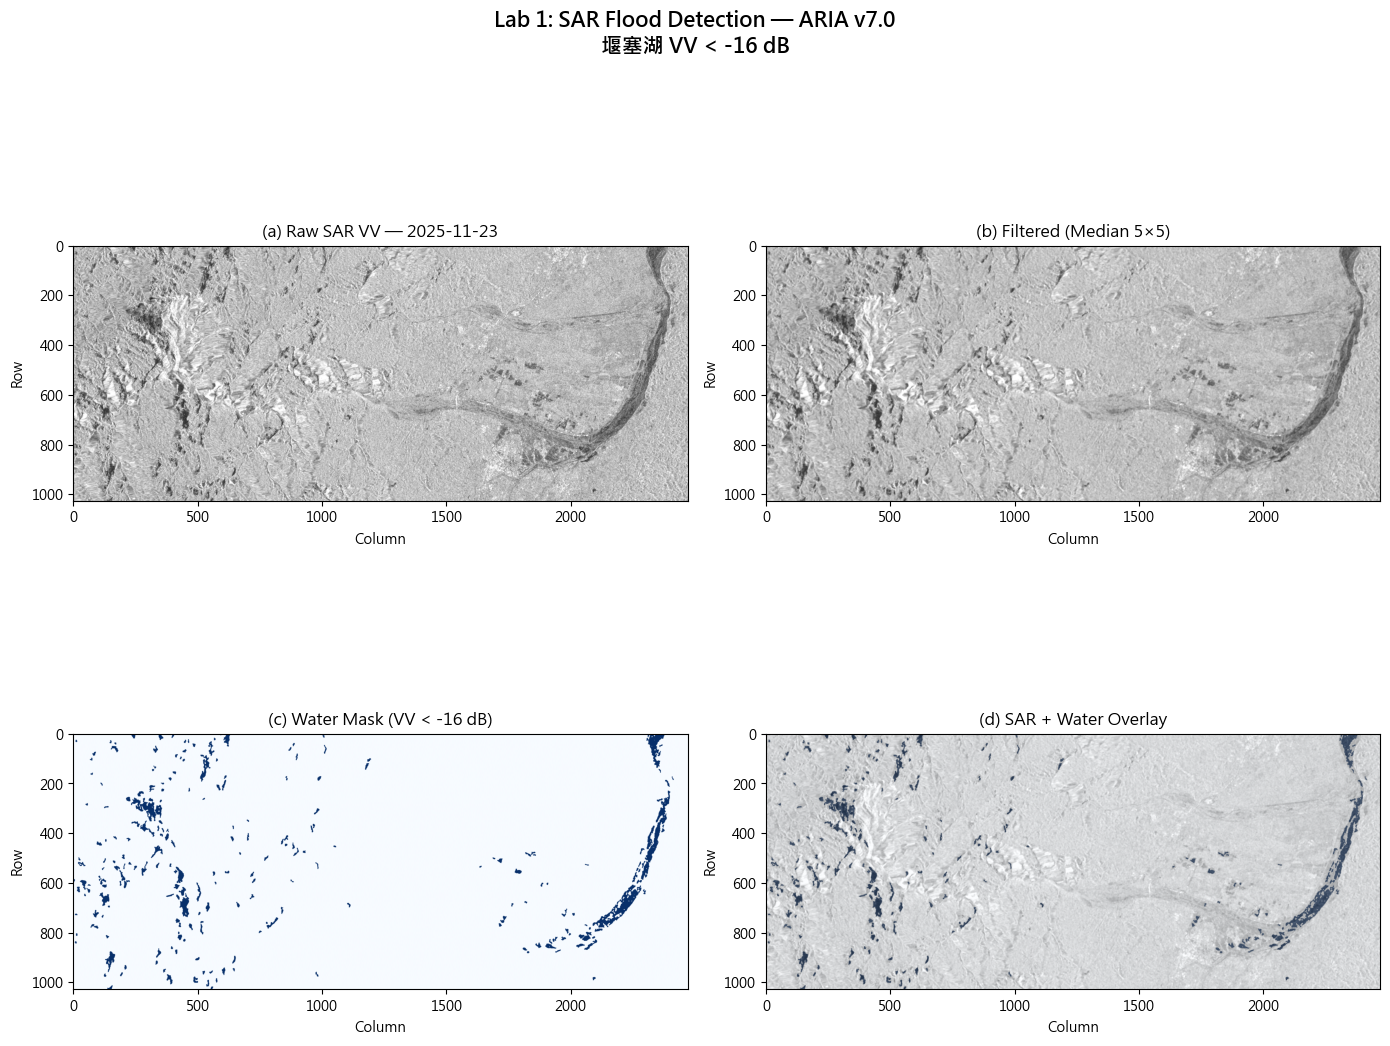

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

axes[0,0].imshow(vv_post_db, cmap='gray', vmin=-30, vmax=0)
axes[0,0].set_title(f'(a) Raw SAR VV — {post_date}')

axes[0,1].imshow(sar_filtered, cmap='gray', vmin=-30, vmax=0)  # <-- TODO: sar_filtered
axes[0,1].set_title('(b) Filtered (Median 5×5)')

axes[1,0].imshow(sar_water, cmap='Blues', vmin=0, vmax=1)    # <-- TODO: sar_water
axes[1,0].set_title(f'(c) Water Mask (VV < {SAR_THRESHOLD} dB)')

axes[1,1].imshow(sar_filtered, cmap='gray', vmin=-30, vmax=0)
axes[1,1].imshow(sar_water, cmap='Blues', alpha=0.4)
axes[1,1].set_title('(d) SAR + Water Overlay')

for ax in axes.flat:
    ax.set_xlabel('Column'); ax.set_ylabel('Row')

plt.suptitle(f'Lab 1: SAR Flood Detection — ARIA v7.0\n堰塞湖 VV < {SAR_THRESHOLD} dB',
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/W10_L1_sar_flood.png', dpi=150, bbox_inches='tight')
plt.show()

### S8. Lab 1 Statistics Table / SAR 水體偵測統計表
---
本段程式將 Lab 1 的 SAR 水體偵測結果整理成統計表，作為成果量化輸出。
程式會計算最終水體遮罩 `sar_water` 中被判定為水體的像素數，並轉換成淹水或堰塞湖面積，單位為平方公里。同時也會計算水體區域內的平均 VV backscatter，檢查偵測出的水體是否具有低回波特徵。

最後，程式會將災後日期、使用的 SAR 門檻、水體像素數、估計水體面積、平均 dB 值，以及最小連通區塊門檻整理成 `stats_df`，並輸出為 `W10_L1_stats.csv`。這個表格可作為 Lab 1 的量化成果，也方便後續與光學影像或其他資料來源比較。

In [8]:
# 10m x 10m pixel
px_area_m2 = 10 * 10
px_area_km2 = px_area_m2 / 1_000_000

water_px = int(np.sum(sar_water == 1))
flood_km2 = water_px * px_area_km2
mean_db_flood = float(np.nanmean(sar_filtered[sar_water == 1])) if water_px > 0 else np.nan

stats_df = pd.DataFrame([{
    "post_date": post_date,
    "sar_threshold_db": SAR_THRESHOLD,
    "water_pixels": water_px,
    "flood_area_km2": round(flood_km2, 4),
    "mean_backscatter_in_flood_db": round(mean_db_flood, 2),
    "min_component_pixels": MIN_WATER_PIXELS
}])

print(stats_df.to_string(index=False))
stats_df.to_csv(f"{OUTPUT_DIR}/W10_L1_stats.csv", index=False)

print(f"\n✅ Task 1 stats saved: {OUTPUT_DIR}/W10_L1_stats.csv")
print(f'SAR detected {flood_km2:.3f} km² of flooding (post-event, threshold {SAR_THRESHOLD} dB).')


 post_date  sar_threshold_db  water_pixels  flood_area_km2  mean_backscatter_in_flood_db  min_component_pixels
2025-11-23               -16         66354          6.6354                        -18.82                    50

✅ Task 1 stats saved: output/W10_L1_stats.csv
SAR detected 6.635 km² of flooding (post-event, threshold -16 dB).


## Task 2. Sentinel-2 Flood Detection

### S8. Search Sentinel-2 for Sensor Fusion / 搜尋 Sentinel-2 光學影像
---
本段程式負責搜尋災後時段的 Sentinel-2 L2A 光學影像，作為後續與 Sentinel-1 SAR 進行感測器融合的資料來源。Sentinel-2 可透過綠光與近紅外波段計算 NDWI，用來偵測水體，但光學影像容易受到雲層遮蔽，因此需要先檢查可用影像的雲量狀況。

程式使用 `robust_search_s2()` 函式在 Microsoft Planetary Computer STAC catalog 中搜尋 `sentinel-2-l2a` collection，搜尋範圍為 `.env` 設定的 `HUALIEN_BBOX`，時間範圍為災後的 `POST_DATE_RANGE`。搜尋結果會依照 `eo:cloud_cover` 由低到高排序。

本段設定 `cloud_max=100`，表示先保留所有雲量範圍內的 Sentinel-2 影像，而不是過早排除高雲量場景。這樣可以完整檢查災後期間光學影像的可用性，並觀察是否因雲層影響而需要依賴 SAR 進行災害監測。

In [9]:
# [S8] Search Sentinel-2 for Fusion (Task 2)

def robust_search_s2(bbox, datetime_range, cloud_max=100, max_items=30, tries=3):
    """Search sentinel-2-l2a and sort by eo:cloud_cover."""
    last_err = None
    for attempt in range(tries):
        try:
            search = catalog.search(
                collections=['sentinel-2-l2a'],
                bbox=bbox,
                datetime=datetime_range,
                max_items=max_items,
            )
            items = list(search.items())
            # 保留雲量欄位存在者，並做 client-side cloud filter
            items = [i for i in items if i.properties.get('eo:cloud_cover', 100) <= cloud_max]
            items.sort(key=lambda i: i.properties.get('eo:cloud_cover', 100))
            return items
        except Exception as e:
            last_err = e
            time.sleep(2 ** attempt)
    raise RuntimeError(f'Sentinel-2 search failed: {last_err}')

# Task2 應用：災後時段 + 花蓮範圍
items_s2 = robust_search_s2(HUALIEN_BBOX, POST_DATE_RANGE, cloud_max=100, max_items=40)

print(f'Sentinel-2 scenes in POST window: {len(items_s2)}')
for i, it in enumerate(items_s2[:10]):
    dt = it.properties.get('datetime', '')[:10]
    cc = it.properties.get('eo:cloud_cover', -1)
    print(f"[{i:02d}] {dt} | cloud: {cc:.1f}% | {it.id}")


Sentinel-2 scenes in POST window: 5
[00] 2025-11-30 | cloud: 44.9% | S2C_MSIL2A_20251130T023051_R046_T51QUG_20251130T052811
[01] 2025-11-22 | cloud: 46.2% | S2A_MSIL2A_20251122T023141_R046_T51QUG_20251122T073215
[02] 2025-11-15 | cloud: 46.2% | S2B_MSIL2A_20251115T022849_R046_T51QUG_20251115T041115
[03] 2025-11-20 | cloud: 75.4% | S2C_MSIL2A_20251120T024011_R046_T51QUG_20251120T052912
[04] 2025-11-25 | cloud: 78.2% | S2B_MSIL2A_20251125T022929_R046_T51QUG_20251125T040807


### T2-C1. Search Sentinel-2 in POST Window / 搜尋災後 Sentinel-2 光學影像
---
本段程式負責搜尋災後時段的 Sentinel-2 L2A 光學影像，作為後續感測器融合分析的資料來源。Sentinel-2 可以用來計算 NDWI 並偵測水體，但光學影像容易受到雲層影響，因此在融合前需要先檢查災後期間有哪些可用場景，以及每張影像的雲量比例。

程式透過 `robust_search_s2()` 函式搜尋 Microsoft Planetary Computer 的 `sentinel-2-l2a` collection，搜尋範圍使用 `HUALIEN_BBOX`，時間範圍使用 `POST_DATE_RANGE`。搜尋過程加入 retry 機制，如果 STAC 查詢暫時失敗，會等待後重新嘗試，提高資料搜尋的穩定性。

In [10]:
# [T2-C1] Search Sentinel-2 in POST window

import time

def robust_search_s2(bbox, datetime_range, cloud_max=100, max_items=40, tries=3):
    last_err = None
    for attempt in range(tries):
        try:
            search = catalog.search(
                collections=['sentinel-2-l2a'],
                bbox=bbox,
                datetime=datetime_range,
                max_items=max_items
            )
            items = list(search.items())
            items = [i for i in items if i.properties.get('eo:cloud_cover', 100) <= cloud_max]
            items.sort(key=lambda i: i.properties.get('eo:cloud_cover', 100))
            return items
        except Exception as e:
            last_err = e
            time.sleep(2 ** attempt)
    raise RuntimeError(f'Sentinel-2 search failed: {last_err}')

items_s2 = robust_search_s2(HUALIEN_BBOX, POST_DATE_RANGE, cloud_max=100, max_items=40)

print(f'Sentinel-2 scenes found: {len(items_s2)}')
for i, it in enumerate(items_s2[:15]):
    dt = it.properties.get('datetime', '')[:10]
    cc = it.properties.get('eo:cloud_cover', -1)
    print(f'[{i:02d}] {dt} | cloud={cc:.1f}% | {it.id}')


Sentinel-2 scenes found: 5
[00] 2025-11-30 | cloud=44.9% | S2C_MSIL2A_20251130T023051_R046_T51QUG_20251130T052811
[01] 2025-11-22 | cloud=46.2% | S2A_MSIL2A_20251122T023141_R046_T51QUG_20251122T073215
[02] 2025-11-15 | cloud=46.2% | S2B_MSIL2A_20251115T022849_R046_T51QUG_20251115T041115
[03] 2025-11-20 | cloud=75.4% | S2C_MSIL2A_20251120T024011_R046_T51QUG_20251120T052912
[04] 2025-11-25 | cloud=78.2% | S2B_MSIL2A_20251125T022929_R046_T51QUG_20251125T040807


### T2-C2. Pick Sentinel-2 Scene Closest to SAR Date / 選擇最接近 SAR 日期的光學影像
---
本段程式會從前一步搜尋到的 Sentinel-2 候選影像中，選出與災後 SAR 影像日期最接近的一張，作為後續 NDWI 與感測器融合使用的光學資料。

這樣做的原因是 SAR 與光學影像如果拍攝日期差距太大，水體範圍可能已經改變，例如水位下降、河道變動或暫時積水消退，導致兩種感測器的結果不容易直接比較。因此，本段不是單純選雲量最低的 Sentinel-2，而是優先選擇時間上最接近 `post_item` 的影像。

如果災後時段完全找不到 Sentinel-2 影像，程式會將 `s2_item` 設為 `None`，後續分析可改用 100% cloudy mode，表示光學資料不可用，SAR 是主要觀測來源。

In [11]:
# [T2-C2] Pick S2 scene closest to post SAR date

from datetime import datetime

if len(items_s2) == 0:
    s2_item = None
    print('No S2 scene in POST window -> fallback to 100% cloudy mode')
else:
    post_dt = datetime.fromisoformat(post_item.properties['datetime'].replace('Z', '+00:00'))
    s2_item = min(
        items_s2,
        key=lambda it: abs(
            (datetime.fromisoformat(it.properties['datetime'].replace('Z', '+00:00')) - post_dt).total_seconds()
        )
    )
    print('Selected S2:', s2_item.properties['datetime'], '| cloud=', s2_item.properties.get('eo:cloud_cover', -1))


Selected S2: 2025-11-22T02:31:41.024000Z | cloud= 46.219483


### T2-C3. Build NDWI and Cloud Mask / 建立 NDWI 水體遮罩與雲遮罩
---
本段程式會使用選定的 Sentinel-2 光學影像建立兩個重要圖層：`ndwi_mask` 與 `cloud_mask`。`ndwi_mask` 用來表示光學影像判定的水體位置，`cloud_mask` 則用來表示哪些區域受到雲或不可用像素影響。

程式首先讀取 Sentinel-2 的 `B03` 綠光波段與 `B08` 近紅外波段，並將資料除以 10000 轉換為反射率。接著計算 NDWI：

\[
NDWI = \frac{Green - NIR}{Green + NIR}
\]

水體通常在綠光反射較高、近紅外反射較低，因此 NDWI 值會偏高。本段使用 `NDWI_THRESHOLD = 0.02`，將 NDWI 大於此門檻的像素判定為光學水體。

接著，程式讀取 Sentinel-2 的 `SCL` 場景分類圖層，建立雲遮罩。程式將不屬於 `[2, 4, 5, 6, 7, 11]` 的像素視為雲、雲影或不可用像素，因此 `cloud_mask = 1` 代表光學資料不可靠，`cloud_mask = 0` 代表光學影像可用。

最後，程式會把 `ndwi_mask` 與 `cloud_mask` 對齊到 SAR 的影像大小，確保後續可以和 `sar_water` 進行逐像素比較。若沒有可用 Sentinel-2 影像，程式會進入 fallback mode，設定為 100% 雲遮，表示此時光學影像無法提供有效證據，主要依賴 SAR 進行水體偵測。

In [12]:
# [T2-C3] Build NDWI + Cloud mask from SCL

import numpy as np
from scipy.ndimage import zoom

H, W = sar_water.shape

if s2_item is not None:
    cube_s2 = stackstac.stack(
        [pc.sign(s2_item)],
        assets=['B03', 'B08'],
        epsg=32651,
        resolution=10,
        bounds_latlon=HUALIEN_BBOX,
        chunksize=2048
    ).squeeze('time') / 10000.0

    green = safe_compute(cube_s2.sel(band='B03')).values
    nir = safe_compute(cube_s2.sel(band='B08')).values
    ndwi = (green - nir) / (green + nir + 1e-9)

    # 建議先用 0.0；若交集太少可再調整
    NDWI_THRESHOLD = 0.02
    ndwi_mask = (ndwi > NDWI_THRESHOLD).astype(np.uint8)   # 1=optical water

    scl_da = safe_compute(
        stackstac.stack(
            [pc.sign(s2_item)],
            assets=['SCL'],
            epsg=32651,
            resolution=10,
            bounds_latlon=HUALIEN_BBOX,
            chunksize=2048
        ).squeeze('time').squeeze('band')
    )
    scl = scl_da.values

    # 1=cloudy/masked
    cloud_mask = (~np.isin(scl, [2, 4, 5, 6, 7, 11])).astype(np.uint8)

    # 對齊到 SAR 網格
    if ndwi_mask.shape != (H, W):
        ndwi_mask = zoom(ndwi_mask, (H / ndwi_mask.shape[0], W / ndwi_mask.shape[1]), order=0)
    if cloud_mask.shape != (H, W):
        cloud_mask = zoom(cloud_mask, (H / cloud_mask.shape[0], W / cloud_mask.shape[1]), order=0)

    print(f'NDWI water px: {int(ndwi_mask.sum()):,}')
    print(f'Cloud-covered ratio: {cloud_mask.mean()*100:.1f}%')
else:
    ndwi = np.full((H, W), np.nan, dtype=np.float32)
    ndwi_mask = np.zeros((H, W), dtype=np.uint8)
    cloud_mask = np.ones((H, W), dtype=np.uint8)  # 全雲遮 fallback
    print('Fallback mode: 100% cloud, no optical evidence')


NDWI water px: 379,006
Cloud-covered ratio: 56.4%


### T2-C5. Optical vs SAR 2×2 Fusion Visualization / 光學與 SAR 融合展示圖
---
本段程式將 SAR 水體偵測、Sentinel-2 雲遮罩、NDWI 光學水體指標，以及光學/SAR 融合結果整理成 2×2 面板圖，用來比較不同感測器在災後水體偵測中的表現。

程式首先將 `sar_water`、`ndwi_mask` 和 `cloud_mask` 轉成二值圖層，分別代表 SAR 判定水體、光學 NDWI 判定水體，以及光學影像受雲遮蔽的區域。接著建立一張 RGB overlay 圖，用不同顏色表示不同類型的偵測結果。

顏色意義如下：

| 顏色 | 代表意義 |
|---|---|
| 黑色 | 沒有偵測到水體 |
| 橘色 | Sentinel-2 雲遮蔽或光學不可用 |
| 綠色 | Optical only，只有 NDWI 判定為水體 |
| 藍色 | SAR only，只有 SAR 判定為水體 |
| 紅色 | Dual evidence，SAR 與光學都判定為水體 |

其中紅色區域代表雙重確認的高信心水體，可信度最高；藍色區域表示 SAR 在光學未確認的地方偵測到低回波水體，可能是雲下水體，也可能包含 radar shadow 或低回波地形；綠色區域則表示光學 NDWI 判定為水體但 SAR 未確認，可能與雲影、濕地、河道反射或兩影像時間差有關。

本圖的目的不是產生最終分類結果，而是作為展示型融合圖，清楚呈現 SAR、光學、雲遮蔽與雙重確認區域之間的空間關係。

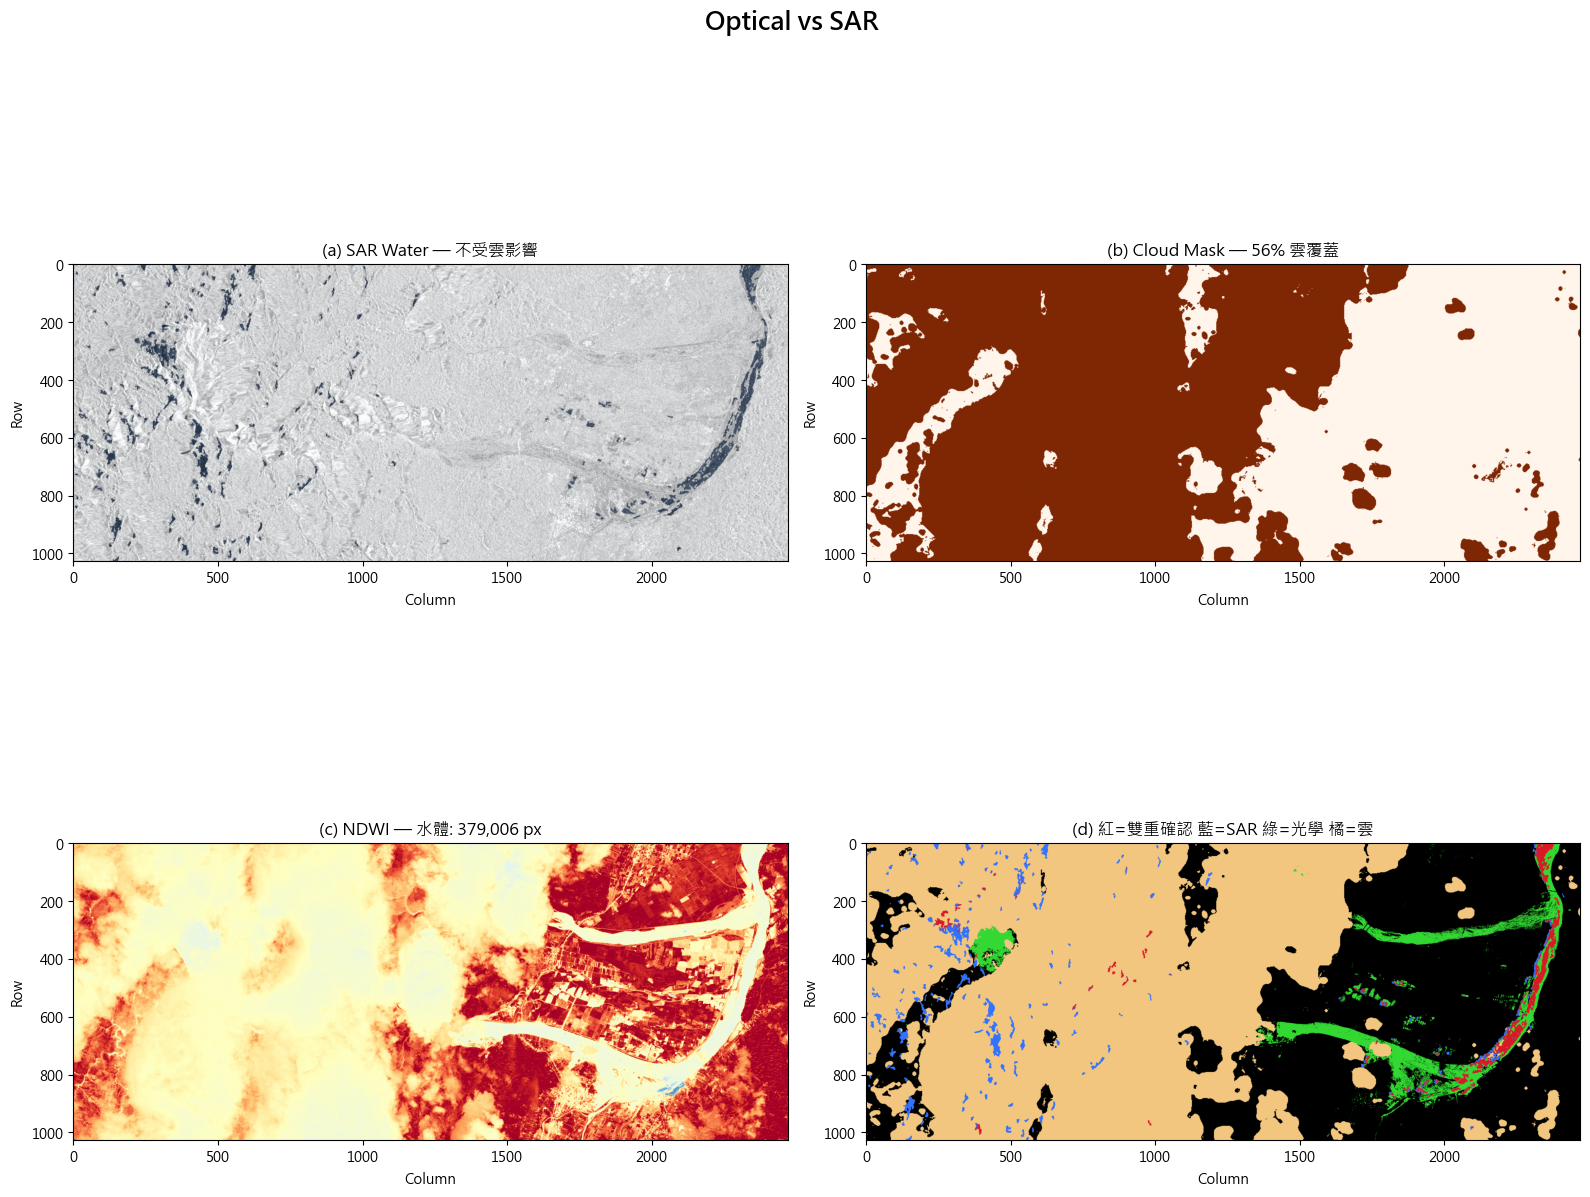

In [13]:
# [T2-C5] 2x2 展示型融合圖（紅=雙重 藍=SAR 綠=光學 橘=雲 黑=無偵測）

import numpy as np
import matplotlib.pyplot as plt

# 確保二值
sar_bin = (sar_water > 0).astype(np.uint8)
opt_bin = (ndwi_mask > 0).astype(np.uint8)
cld_bin = (cloud_mask > 0).astype(np.uint8)   # 1=cloudy

# 先做「展示 overlay」
overlay = np.zeros((*sar_bin.shape, 3), dtype=np.float32)

# 黑：No detection（預設）
overlay[:] = [0.0, 0.0, 0.0]

# 橘：Cloud
overlay[cld_bin == 1] = [0.95, 0.78, 0.50]

# 綠：Optical only（清空區）
overlay[(opt_bin == 1) & (sar_bin == 0) & (cld_bin == 0)] = [0.20, 0.85, 0.20]

# 藍：SAR only（可在全域標示）
overlay[(sar_bin == 1) & (opt_bin == 0)] = [0.20, 0.45, 1.00]

# 紅：Dual evidence（最高優先權，最後蓋）
overlay[(sar_bin == 1) & (opt_bin == 1)] = [0.85, 0.10, 0.15]

# 2x2 圖
fig, axes = plt.subplots(2, 2, figsize=(16, 14))

# (a) SAR + 底圖
axes[0,0].imshow(vv_post_db, cmap='gray', vmin=-30, vmax=0)
axes[0,0].imshow(sar_bin, cmap='Blues', alpha=0.35, vmin=0, vmax=1)
axes[0,0].set_title('(a) SAR Water — 不受雲影響')

# (b) Cloud mask
axes[0,1].imshow(cld_bin, cmap='Oranges', vmin=0, vmax=1)
axes[0,1].set_title(f'(b) Cloud Mask — {cld_bin.mean()*100:.0f}% 雲覆蓋')

# (c) NDWI
if 'ndwi' in globals() and np.isfinite(ndwi).any():
    axes[1,0].imshow(ndwi, cmap='RdYlBu', vmin=-0.5, vmax=0.5)
else:
    axes[1,0].imshow(opt_bin, cmap='Greens', vmin=0, vmax=1)
axes[1,0].set_title(f'(c) NDWI — 水體: {int(opt_bin.sum()):,} px')

# (d) 融合展示圖
axes[1,1].imshow(overlay)
axes[1,1].set_title('(d) 紅=雙重確認 藍=SAR 綠=光學 橘=雲')

for ax in axes.flat:
    ax.set_xlabel('Column')
    ax.set_ylabel('Row')

plt.suptitle('Optical vs SAR ', fontsize=18, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/W10_task2_optical_vs_sar_2x2.png', dpi=150, bbox_inches='tight')
plt.show()


### S10. Build 4-Class Confidence Map / 建立四類融合信心圖
---
本段程式將 SAR 水體遮罩、光學 NDWI 水體遮罩，以及 Sentinel-2 雲遮罩整合成一張四類別的 `fusion` 信心圖。這張圖的目的不是單純判斷「有水 / 沒水」，而是根據不同資料來源的支持程度，區分水體偵測的可信度。

分類邏輯如下：

| 類別值 | 類別名稱 | 判斷條件 | 意義 |
|---:|---|---|---|
| 0 | No Detection | SAR 與光學皆未偵測 | 沒有水體證據 |
| 1 | Optical Only | 只有 NDWI 偵測，且非雲區 | 光學判定水體，但 SAR 未確認 |
| 2 | SAR Only (Cloudy) | 雲遮區中 SAR 偵測為水 | SAR 在光學受雲影響區提供水體證據 |
| 3 | High Confidence | SAR 與 NDWI 都偵測為水 | 雙重證據，可信度最高 |

其中，`High Confidence` 代表同一像素同時被 SAR 與光學判定為水體，因此是最可靠但也最保守的水體範圍。`SAR Only (Cloudy)` 則強調 SAR 在雲遮區的價值，因為光學影像在這些區域無法有效觀測地表。

程式最後會計算每一類別的像素數與面積，並將面積轉換為平方公里。這些統計結果會輸出成 `W10_task2_confidence_stats.csv`，作為 Task 2 的量化成果與後續報告比較使用。

In [14]:
# 保證是 0/1 二值
sar_bin = (sar_water > 0).astype(np.uint8)
opt_bin = (ndwi_mask > 0).astype(np.uint8)
cld_bin = (cloud_mask > 0).astype(np.uint8)   # 1=cloudy

assert sar_bin.shape == opt_bin.shape == cld_bin.shape, "shape mismatch"

fusion = np.zeros_like(sar_bin, dtype=np.uint8)

# High Confidence（雙重證據）
fusion[(opt_bin == 1) & (sar_bin == 1)] = 3

# SAR Only (Cloudy)（避免覆蓋 High）
fusion[(cld_bin == 1) & (sar_bin == 1) & (fusion != 3)] = 2

# Optical Only（清空區）
fusion[(opt_bin == 1) & (sar_bin == 0) & (cld_bin == 0)] = 1

labels = {
    0: "No Detection",
    1: "Optical Only",
    2: "SAR Only (Cloudy)",
    3: "High Confidence"
}

# 面積換算
px_area_ha = (10 * 10) / 10000  # 0.01 ha/px
px_area_km2 = (10 * 10) / 1_000_000  # 0.0001 km²/px

print("Fusion result:")
for v, lbl in labels.items():
    n = int(np.sum(fusion == v))
    print(f"  {lbl}: {n:,} px = {n * px_area_km2:.3f} km²")

# 輸出 fusion 統計表到 CSV
import pandas as pd

rows = []
for v, lbl in labels.items():
    n = int(np.sum(fusion == v))
    rows.append({
        "class_id": v,
        "class_name": lbl,
        "pixels": n,
        "area_km2": n * px_area_km2
    })

fusion_stats_df = pd.DataFrame(rows).sort_values("class_id")
display(fusion_stats_df)

csv_path = f"{OUTPUT_DIR}/W10_task2_confidence_stats.csv"
fusion_stats_df.to_csv(csv_path, index=False, encoding="utf-8-sig")
print(f"Saved CSV: {csv_path}")



Fusion result:
  No Detection: 2,370,929 px = 237.093 km²
  Optical Only: 106,952 px = 10.695 km²
  SAR Only (Cloudy): 29,280 px = 2.928 km²
  High Confidence: 27,059 px = 2.706 km²


,class_id,class_name,pixels,area_km2
0,0,No Detection,2370929,237.0929
1,1,Optical Only,106952,10.6952
2,2,SAR Only (Cloudy),29280,2.9280
3,3,High Confidence,27059,2.7059


Saved CSV: output/W10_task2_confidence_stats.csv


### Task 2 discussion:
    High confidence zones cover 2.706 km². SAR-only zones add 2.928 km² of flood detection in cloudy areas.

---
---
## Task 3. Terrain Correction：利用坡度移除淹水區
---
---

### Topographic Correction：利用坡度移除山區誤判淹水區
---
    這段程式的目的，是使用 Copernicus DEM 計算地形坡度，並把坡度過陡的區域從淹水偵測結果中移除。因為真正的淹水通常發生在低平地區，若在高坡度山區出現水體偵測，較可能是 SAR 或光學影像造成的誤判。
---
1. 設定坡度門檻與 SAR 解析度
    - 首先設定坡度門檻 `SLOPE_THRESHOLD = 25`。如果前面已經設定過這個變數，就保留原本的值；如果沒有，則預設為 25 度。同時設定 SAR 影像解析度為 10 公尺，用來後續計算移除面積。

2. 下載並讀取 Copernicus DEM
    - 透過 Planetary Computer 的 STAC API 搜尋研究區域內的 Copernicus DEM 資料，並使用 `stackstac` 將 DEM 讀入成陣列。這個 DEM 提供地表高程資訊，是後續計算坡度的基礎資料。

3. 計算坡度圖
    - 使用 DEM 的高程變化計算 x 與 y 方向的梯度，接著轉換成坡度角度。程式會將坡度單位轉成 degree，方便用 25 度、35 度、45 度等門檻進行判斷。

4. 對齊坡度圖與 Fusion Map
    - 因為 DEM 的解析度是 30 公尺，而 SAR / Fusion Map 的解析度是 10 公尺，所以兩者網格大小不同。這一步使用 `ndi.zoom()` 將坡度圖重新取樣，使它的 shape 與 `fusion` 完全一致，才能逐像素比較。

5. 移除高坡度地區的淹水誤判
    - 程式將 `fusion` 中的 1、2、3 類視為可能淹水區，並找出其中坡度大於 `SLOPE_THRESHOLD` 的像素。這些像素被視為地形上不合理的淹水偵測，因此重新標記為 0，也就是 `No Detection`。

6. 統計與視覺化修正結果
    - 最後程式統計被移除的像素數與面積，並依照坡度區間分成 `25–35°`、`35–45°`、`>45°`。接著繪製修正前後的 Fusion Map，讓使用者可以直接比較地形校正前後，哪些山區誤判被移除了。

     Slope Class  Removed Pixels  Removed Area (km²)
0         25-35°           10230              1.0230
1         35-45°           12050              1.2050
2           >45°           18027              1.8027
3  Total Removed           40307              4.0307


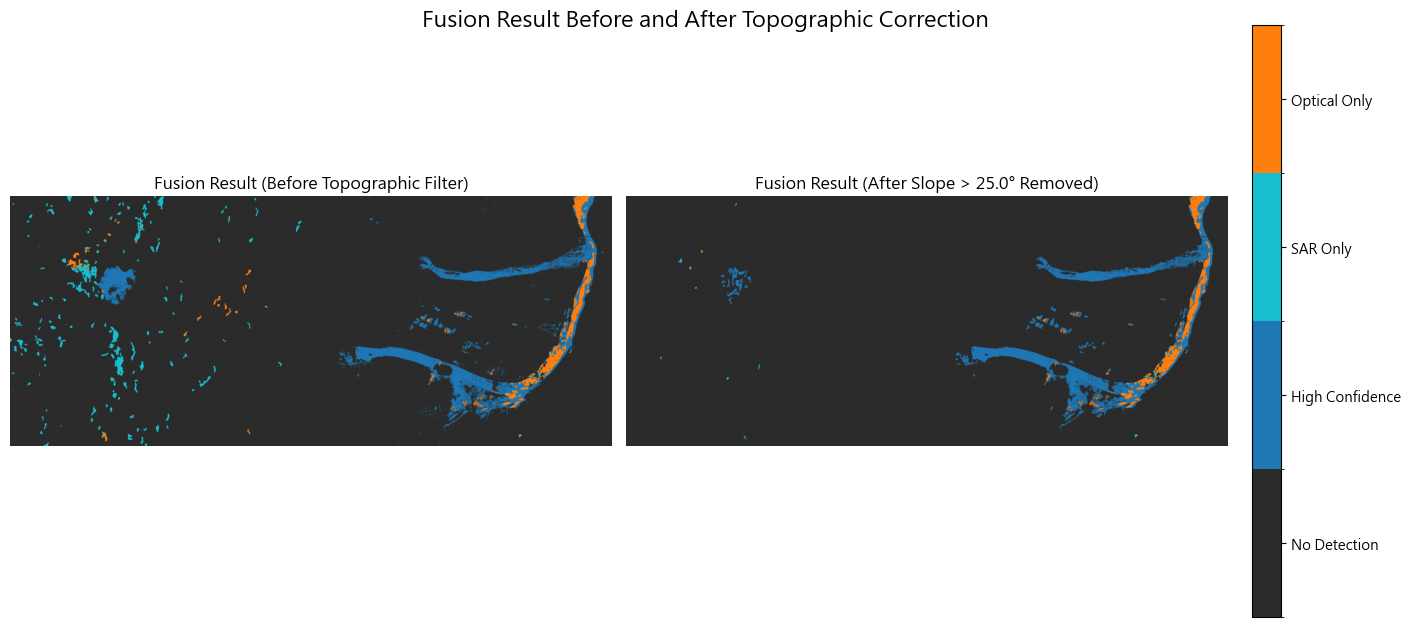

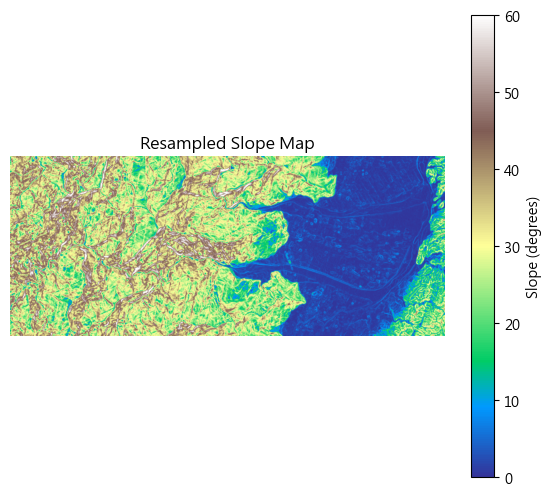

In [ ]:
from scipy import ndimage as ndi

SLOPE_THRESHOLD = 25 if 'SLOPE_THRESHOLD' not in globals() else SLOPE_THRESHOLD
sar_res_m = 10 

# ---- 1) Load Copernicus DEM from STAC ----
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=pc.sign_inplace
)

dem_search = catalog.search(
    collections=["cop-dem-glo-30"],
    bbox=HUALIEN_BBOX
)
dem_items = list(dem_search.items())
if len(dem_items) == 0:
    raise RuntimeError("No DEM items found in bbox.")

dem_da = stackstac.stack(
    [pc.sign(item) for item in dem_items],
    assets=["data"],
    bounds_latlon=HUALIEN_BBOX,
    epsg=32651,
    resolution=30
).squeeze("time").compute()
dem = np.asarray(dem_da.values).astype(np.float32)
dem = np.squeeze(dem)
dem = np.where(np.isfinite(dem), dem, np.nan)

# ---- 2) Compute slope (degrees) ----
# Use 30m spacing for DEM gradient
dy, dx = np.gradient(dem, 30.0, 30.0)
slope_deg = np.degrees(np.arctan(np.sqrt(dx**2 + dy**2)))

# Fill nan slope with 0 to avoid blocking valid flood pixels at edges
slope_deg = np.nan_to_num(slope_deg, nan=0.0)

# ---- 3) Align slope grid to fusion/SAR grid ----
target_shape = fusion.shape
zoom_y = target_shape[0] / slope_deg.shape[0]
zoom_x = target_shape[1] / slope_deg.shape[1]
slope_resampled = ndi.zoom(slope_deg, (zoom_y, zoom_x), order=1)  # bilinear

assert slope_resampled.shape == fusion.shape, "Slope and fusion grid mismatch."

# ---- 4) Topographic filter ----
# Flood-like classes assumed: 1,2,3 ; no-detection: 0
flood_like = np.isin(fusion, [1, 2, 3])
steep_mask = slope_resampled > SLOPE_THRESHOLD

fusion_map_after = fusion.copy()
false_positive_mask = flood_like & steep_mask
fusion_map_after[false_positive_mask] = 0  # remove steep-terrain flood detections

# Optional post-cleanup (small isolated remnants)
# Keep connected components >= MIN_WATER_PIXELS if provided
if 'MIN_WATER_PIXELS' in globals():
    post_flood = np.isin(fusion_map_after, [1, 2, 3])
    lbl, n = ndi.label(post_flood)
    if n > 0:
        counts = np.bincount(lbl.ravel())
        keep = counts >= MIN_WATER_PIXELS
        keep[0] = False
        remove_small = post_flood & (~keep[lbl])
        fusion_map_after[remove_small] = 0

# ---- 5) Stats by slope class ----
pixel_area_km2 = (sar_res_m * sar_res_m) / 1e6

removed_25_35 = false_positive_mask & (slope_resampled > 25) & (slope_resampled <= 35)
removed_35_45 = false_positive_mask & (slope_resampled > 35) & (slope_resampled <= 45)
removed_gt45  = false_positive_mask & (slope_resampled > 45)

stats_df = pd.DataFrame({
    "Slope Class": ["25-35°", "35-45°", ">45°", "Total Removed"],
    "Removed Pixels": [
        int(removed_25_35.sum()),
        int(removed_35_45.sum()),
        int(removed_gt45.sum()),
        int(false_positive_mask.sum())
    ]
})
stats_df["Removed Area (km²)"] = stats_df["Removed Pixels"] * pixel_area_km2

print(stats_df)

# ---- 6) Visualization: before vs after ----
# same palette as task2 (example)
cmap = mcolors.ListedColormap(["#2b2b2b", "#1f77b4", "#17becf", "#ff7f0e"])
norm = mcolors.BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], cmap.N)

fig, ax = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)
im0 = ax[0].imshow(fusion, cmap=cmap, norm=norm)
ax[0].set_title("Fusion Result (Before Topographic Filter)")
ax[0].axis("off")

im1 = ax[1].imshow(fusion_map_after, cmap=cmap, norm=norm)
ax[1].set_title(f"Fusion Result (After Slope > {SLOPE_THRESHOLD}° Removed)")
ax[1].axis("off")

cbar = fig.colorbar(im1, ax=ax, fraction=0.03, pad=0.02, ticks=[0, 1, 2, 3])
cbar.ax.set_yticklabels(["No Detection", "High Confidence", "SAR Only", "Optical Only"])
fig.suptitle("Fusion Result Before and After Topographic Correction", fontsize=16, y=1.02)
plt.show()

# Optional: slope map quicklook
plt.figure(figsize=(7, 6))
plt.imshow(slope_resampled, cmap="terrain", vmin=0, vmax=60)
plt.colorbar(label="Slope (degrees)")
plt.title("Resampled Slope Map")
plt.axis("off")
plt.show()


### 被坡度濾掉的誤判淹水區統計
---
有多少原本被判定為淹水的像素，因為位在高坡度地區，所以被視為誤判並移除。

In [24]:
pixel_area_km2 = (sar_res_m * sar_res_m) / 1e6

removed_25_35 = false_positive_mask & (slope_resampled > 25) & (slope_resampled <= 35)
removed_35_45 = false_positive_mask & (slope_resampled > 35) & (slope_resampled <= 45)
removed_gt45  = false_positive_mask & (slope_resampled > 45)

stats_df = pd.DataFrame({
    "Slope Class": ["25-35°", "35-45°", ">45°", "Total Removed"],
    "Removed Pixels": [
        int(removed_25_35.sum()),
        int(removed_35_45.sum()),
        int(removed_gt45.sum()),
        int(false_positive_mask.sum())
    ]
})
stats_df["Removed Area (km²)"] = stats_df["Removed Pixels"] * pixel_area_km2

os.makedirs("output", exist_ok=True)
out_csv = "output/task3_false_positives_by_slope_class.csv"
stats_df.to_csv(out_csv, index=False, encoding="utf-8-sig")

print(stats_df)
print(f"Saved: {out_csv}")


     Slope Class  Removed Pixels  Removed Area (km²)
0         25-35°           10230              1.0230
1         35-45°           12050              1.2050
2           >45°           18027              1.8027
3  Total Removed           40307              4.0307
Saved: output/task3_false_positives_by_slope_class.csv
